Importing the Libraries

In [1]:
# Topic: Libraries We Need

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

What is Logistic Regression

In [2]:
# Topic: What is Logistic Regression
# Logistic regression is used when the answer is a CLASS, like Yes/No or 0/1.
# It gives the probability that something belongs to a class,
# for example: "Is this email spam?" or "Will this student pass?"
#
# It starts with the same linear equation as linear regression:
#     z = b0 + b1*x1 + b2*x2 + ...
# and then passes z through the sigmoid function to turn it into a probability.

b0, b1 = -6, 1.5          # example intercept and slope
hours = 5                 # example input
z = b0 + b1 * hours
print("Linear part z =", z)

Linear part z = 1.5


The Sigmoid Function

z = -4 -> probability = 0.018 -> class 0
z = -1 -> probability = 0.269 -> class 0
z =  0 -> probability = 0.500 -> class 1
z =  1 -> probability = 0.731 -> class 1
z =  4 -> probability = 0.982 -> class 1


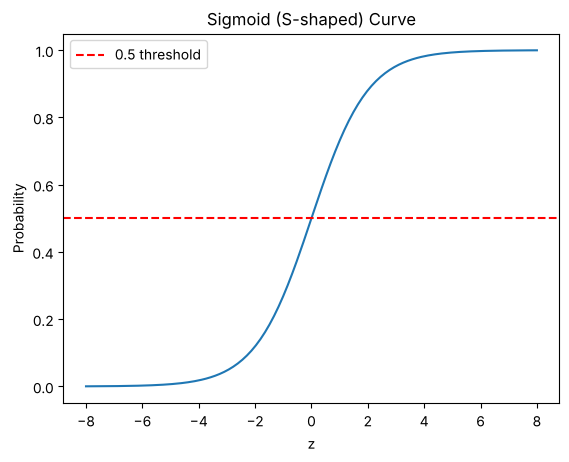

In [3]:
# Topic: Sigmoid Function
# The sigmoid squeezes any number into a value between 0 and 1:
#     sigmoid(z) = 1 / (1 + e^(-z))
# If the result is 0.5 or more we say class 1, otherwise class 0.

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

for z in [-4, -1, 0, 1, 4]:
    p = sigmoid(z)
    print(f"z = {z:>2} -> probability = {p:.3f} -> class {int(p >= 0.5)}")

z_values = np.linspace(-8, 8, 200)
plt.plot(z_values, sigmoid(z_values))
plt.axhline(0.5, color="red", linestyle="--", label="0.5 threshold")
plt.title("Sigmoid (S-shaped) Curve")
plt.xlabel("z")
plt.ylabel("Probability")
plt.legend()
plt.show()

Properties of Logistic Regression

In [4]:
# Topic: Properties
# 1. The output (dependent variable) is a category, usually 0 or 1
# 2. The model predicts a probability between 0 and 1
# 3. The parameters are found using Maximum Likelihood Estimation (MLE)
# 4. The decision boundary is where the probability is exactly 0.5

properties = [
    "Target is categorical (for example 0 or 1)",
    "Output is a probability between 0 and 1",
    "Parameters are learned with Maximum Likelihood Estimation",
    "Probability >= 0.5 means class 1, otherwise class 0",
]
for i, p in enumerate(properties, 1):
    print(i, p)

1 Target is categorical (for example 0 or 1)
2 Output is a probability between 0 and 1
3 Parameters are learned with Maximum Likelihood Estimation
4 Probability >= 0.5 means class 1, otherwise class 0


Linear Regression vs Logistic Regression

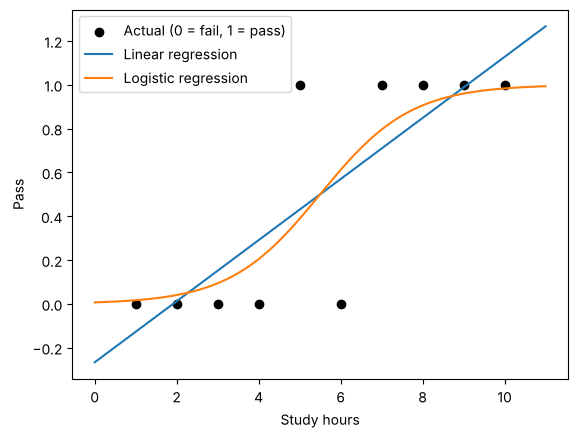

Linear model at 0 hours : -0.27 (below 0, not a valid probability)
Logistic model at 0 hours: 0.01


In [5]:
# Topic: Linear vs Logistic
# Linear regression predicts a continuous number (like a price).
# Logistic regression predicts a class (like pass or fail).
# Below, a straight line gives values below 0 and above 1, which make no sense
# as probabilities, while the sigmoid always stays between 0 and 1.

hours = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
passed = np.array([0, 0, 0, 0, 1, 0, 1, 1, 1, 1])

from sklearn.linear_model import LinearRegression, LogisticRegression

lin = LinearRegression().fit(hours.reshape(-1, 1), passed)
log = LogisticRegression().fit(hours.reshape(-1, 1), passed)

grid = np.linspace(0, 11, 100).reshape(-1, 1)
plt.scatter(hours, passed, color="black", label="Actual (0 = fail, 1 = pass)")
plt.plot(grid, lin.predict(grid), label="Linear regression")
plt.plot(grid, log.predict_proba(grid)[:, 1], label="Logistic regression")
plt.xlabel("Study hours")
plt.ylabel("Pass")
plt.legend()
plt.show()

print("Linear model at 0 hours :", round(lin.predict([[0]])[0], 2), "(below 0, not a valid probability)")
print("Logistic model at 0 hours:", round(log.predict_proba([[0]])[0, 1], 2))

Maximum Likelihood Estimation vs Least Squares Method

In [6]:
# Topic: MLE vs Least Squares
# Least squares (used by linear regression) finds the line with the
# smallest total squared error.
# Maximum Likelihood Estimation (used by logistic regression) finds the
# parameters that make the real answers as LIKELY as possible.
# Here we compare the likelihood of two different models on the pass/fail data.

def likelihood(b0, b1):
    p = sigmoid(b0 + b1 * hours)
    # probability of what actually happened, multiplied over all students
    return np.prod(np.where(passed == 1, p, 1 - p))

print("Likelihood of a poor model  (b0=0,  b1=0.1):", likelihood(0, 0.1))
print("Likelihood of a better model (b0=-6, b1=1.2):", likelihood(-6, 1.2))
print("Learned by sklearn: b0 =", round(log.intercept_[0], 2), "b1 =", round(log.coef_[0][0], 2))
print("Likelihood of sklearn's model:", likelihood(log.intercept_[0], log.coef_[0][0]))

Likelihood of a poor model  (b0=0,  b1=0.1): 0.0019301197370389567
Likelihood of a better model (b0=-6, b1=1.2): 0.06951821840948544
Learned by sklearn: b0 = -4.98 b1 = 0.91
Likelihood of sklearn's model: 0.06987910563570536


Types of Logistic Regression

In [7]:
# Topic: Types
# 1. Binary      -> two classes, e.g. spam / not spam
# 2. Multinomial -> three or more classes with no order, e.g. cat / dog / bird
# 3. Ordinal     -> three or more classes with an order, e.g. low / medium / high

types = pd.DataFrame({
    "Type": ["Binary", "Multinomial", "Ordinal"],
    "Classes": ["2", "3 or more (no order)", "3 or more (ordered)"],
    "Example": ["Pass / Fail", "Apple / Mango / Banana", "Poor / Average / Good"],
})
print(types.to_string(index=False))

       Type              Classes                Example
     Binary                    2            Pass / Fail
Multinomial 3 or more (no order) Apple / Mango / Banana
    Ordinal  3 or more (ordered)  Poor / Average / Good


Model Building: Loading Data

In [8]:
# Topic: Loading the Data
# We use the breast cancer dataset that comes with sklearn.
# Each row is a tumor; the target is 0 = malignant (cancer) and 1 = benign (not cancer).

from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

print("Shape:", df.shape)
print(df.iloc[:5, :6])
print("\nClass counts (0 = malignant, 1 = benign):")
print(df["target"].value_counts())

Shape: (569, 31)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  
0           0.27760  
1           0.07864  
2           0.15990  
3           0.28390  
4           0.13280  

Class counts (0 = malignant, 1 = benign):
target
1    357
0    212
Name: count, dtype: int64


Selecting Features

In [9]:
# Topic: Selecting Features
# Features (X) are the inputs; the target (y) is what we want to predict.
# We pick 8 features to keep the model simple.

feature_cols = ["mean radius", "mean texture", "mean perimeter", "mean area",
                "mean smoothness", "mean compactness", "mean concavity", "mean symmetry"]

X = df[feature_cols]
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 8)
y shape: (569,)


Splitting Data

In [10]:
# Topic: Train/Test Split (75:25)
# 75% of the rows are used to train and 25% to test

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=16)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 426
Testing rows: 143


Model Development and Prediction

In [11]:
# Topic: Training and Predicting
# max_iter gives the model enough steps to finish learning

logreg = LogisticRegression(random_state=16, max_iter=10000)
logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)
print("First 10 predictions:", y_pred[:10])
print("First 10 actual     :", y_test.values[:10])

# predict_proba() gives the probability of each class
print("\nProbabilities for the first 3 tumors [malignant, benign]:")
print(logreg.predict_proba(X_test[:3]).round(3))

First 10 predictions: [1 1 1 1 1 1 1 1 0 1]
First 10 actual     : [1 1 1 1 1 1 1 1 0 1]

Probabilities for the first 3 tumors [malignant, benign]:
[[0.015 0.985]
 [0.015 0.985]
 [0.462 0.538]]


Model Evaluation using Confusion Matrix

In [12]:
# Topic: Confusion Matrix
# Rows are the actual classes and columns are the predicted classes.
# The diagonal shows correct predictions; the other cells show mistakes.

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

tn, fp, fn, tp = cm.ravel()
print(f"Correct: {tn + tp} | Wrong: {fp + fn}")

[[45  7]
 [ 5 86]]
Correct: 131 | Wrong: 12


Visualizing Confusion Matrix using a Heatmap

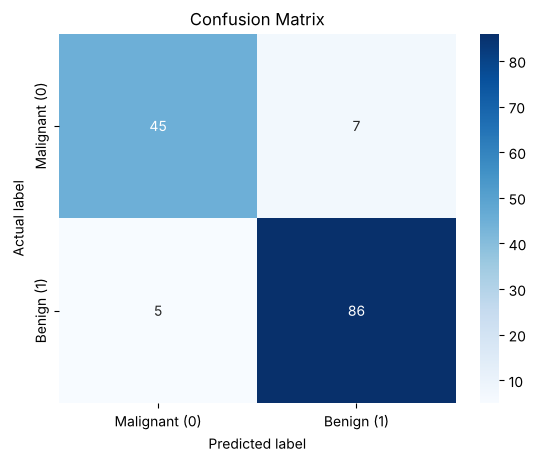

In [13]:
# Topic: Confusion Matrix as a Heatmap

labels = ["Malignant (0)", "Benign (1)"]
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.show()

Confusion Matrix Evaluation Metrics

In [14]:
# Topic: Accuracy, Precision, Recall and F1
# Accuracy  -> how many predictions were correct overall
# Precision -> of the tumors predicted as a class, how many really were that class
# Recall    -> of the real tumors in a class, how many the model found
# F1-score  -> balance between precision and recall

from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print()
print(classification_report(y_test, y_pred, target_names=["malignant", "benign"]))

Accuracy: 0.916

              precision    recall  f1-score   support

   malignant       0.90      0.87      0.88        52
      benign       0.92      0.95      0.93        91

    accuracy                           0.92       143
   macro avg       0.91      0.91      0.91       143
weighted avg       0.92      0.92      0.92       143



ROC Curve

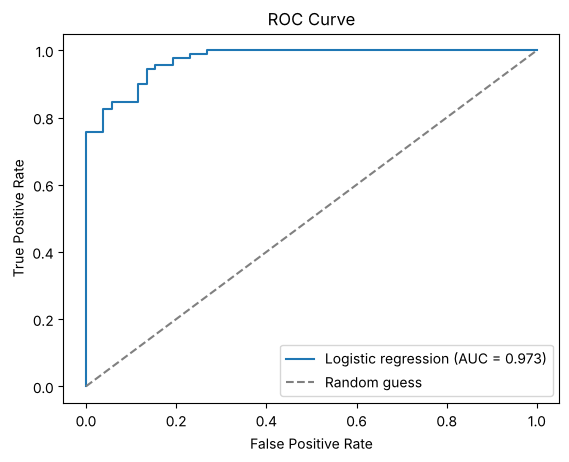

In [15]:
# Topic: ROC Curve and AUC
# The ROC curve shows the true positive rate against the false positive rate
# for every possible threshold. AUC is the area under it:
# 1.0 is perfect and 0.5 is no better than guessing.

from sklearn.metrics import roc_curve, roc_auc_score

y_prob = logreg.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

Advantages and Disadvantages

In [16]:
# Topic: Advantages and Disadvantages

advantages = [
    "Simple and fast to train",
    "Easy to understand: each feature has its own coefficient",
    "Gives probabilities, not just class labels",
    "Does not need feature scaling to work",
]
disadvantages = [
    "Does not handle a large number of categorical features well",
    "Can overfit when there are too many features",
    "Cannot model non-linear relationships on its own",
]

print("Advantages:")
for a in advantages:
    print(" +", a)
print("Disadvantages:")
for d in disadvantages:
    print(" -", d)

Advantages:
 + Simple and fast to train
 + Easy to understand: each feature has its own coefficient
 + Gives probabilities, not just class labels
 + Does not need feature scaling to work
Disadvantages:
 - Does not handle a large number of categorical features well
 - Can overfit when there are too many features
 - Cannot model non-linear relationships on its own


Handwriting Recognition: Loading the Digits Dataset

In [17]:
# Topic: Multiclass Logistic Regression on Handwritten Digits
# The digits dataset has 1797 small images (8 x 8 pixels) of the digits 0 to 9.
# Each image is stored as 64 numbers (one per pixel).

from sklearn.datasets import load_digits

digits = load_digits()

print("Image data shape:", digits.data.shape)    # 1797 images, 64 pixels each
print("Label data shape:", digits.target.shape)

Image data shape: (1797, 64)
Label data shape: (1797,)


Showing the Images and Labels

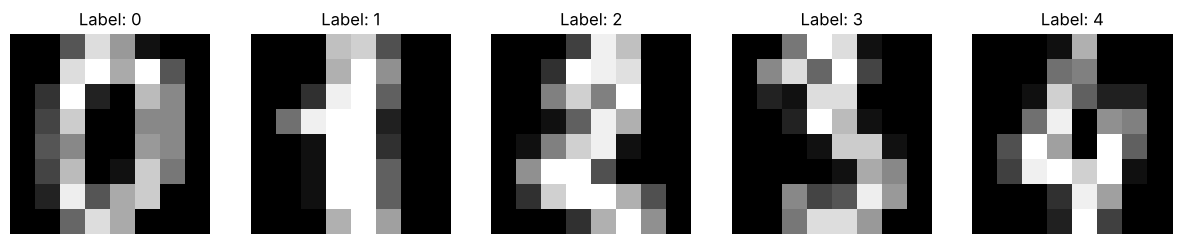

In [18]:
# Topic: Looking at Some Digits

plt.figure(figsize=(15, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(digits.data[i].reshape(8, 8), cmap=plt.cm.gray)
    plt.title(f"Label: {digits.target[i]}")
    plt.axis("off")
plt.show()

Splitting the Digits Data

In [19]:
# Topic: Train/Test Split for Digits

x_train, x_test, d_train, d_test = train_test_split(
    digits.data, digits.target, test_size=0.25, random_state=0)

print("Training images:", x_train.shape[0])
print("Testing images:", x_test.shape[0])

Training images: 1347
Testing images: 450


Training the Digits Model

In [20]:
# Topic: Training on 10 Classes
# The same LogisticRegression handles 10 classes automatically (multinomial)

digit_model = LogisticRegression(max_iter=5000)
digit_model.fit(x_train, d_train)
print("Model trained on", len(digit_model.classes_), "classes:", digit_model.classes_)

Model trained on 10 classes: [0 1 2 3 4 5 6 7 8 9]


Predicting Digits

In [21]:
# Topic: Making Predictions

# Predict one image
print("Prediction for the first test image:", digit_model.predict(x_test[0].reshape(1, -1))[0])
print("Actual label                       :", d_test[0])

# Predict the first 10 images at once
print("Predicted:", digit_model.predict(x_test[:10]))
print("Actual   :", d_test[:10])

# Predict all test images
d_pred = digit_model.predict(x_test)

Prediction for the first test image: 2
Actual label                       : 2
Predicted: [2 8 2 6 6 7 1 9 8 5]
Actual   : [2 8 2 6 6 7 1 9 8 5]


Measuring Model Performance

In [22]:
# Topic: Accuracy with score()
# score() gives the accuracy: correct predictions / total predictions

accuracy = digit_model.score(x_test, d_test)
print(f"Accuracy on test images: {accuracy:.3f}")

Accuracy on test images: 0.953


Confusion Matrix for Digits

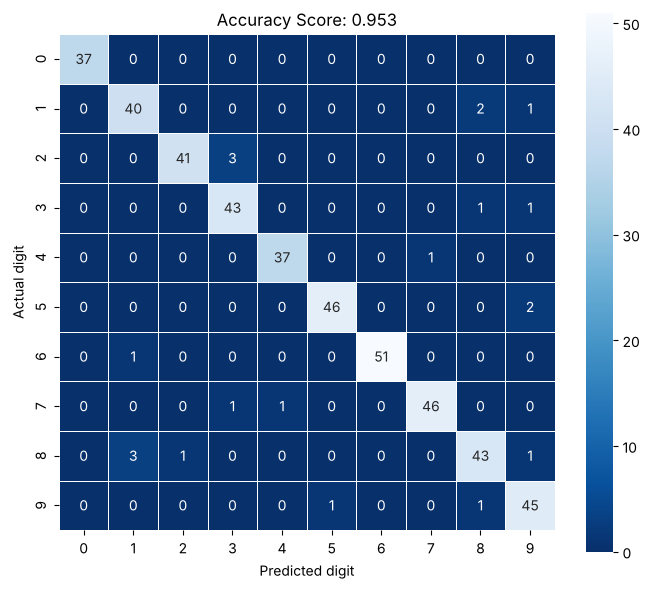

In [23]:
# Topic: 10 x 10 Confusion Matrix
# Each row is the real digit, each column is the predicted digit

cm_digits = confusion_matrix(d_test, d_pred)

plt.figure(figsize=(8, 7))
sns.heatmap(cm_digits, annot=True, fmt="d", cmap="Blues_r", linewidths=0.5, square=True)
plt.xlabel("Predicted digit")
plt.ylabel("Actual digit")
plt.title(f"Accuracy Score: {accuracy:.3f}")
plt.show()

Showing Misclassified Images

Number of wrong predictions: 21


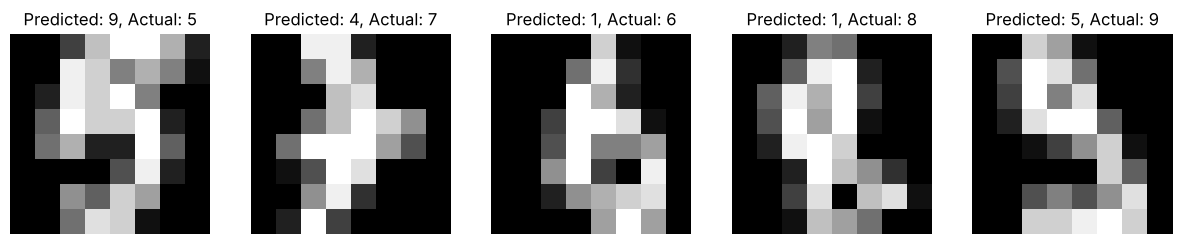

In [24]:
# Topic: Where Did the Model Go Wrong?
# We find the test images where the prediction was wrong and show a few of them

wrong = np.where(d_pred != d_test)[0]
print("Number of wrong predictions:", len(wrong))

plt.figure(figsize=(15, 3))
for plot_i, idx in enumerate(wrong[:5]):
    plt.subplot(1, 5, plot_i + 1)
    plt.imshow(x_test[idx].reshape(8, 8), cmap=plt.cm.gray)
    plt.title(f"Predicted: {d_pred[idx]}, Actual: {d_test[idx]}")
    plt.axis("off")
plt.show()

Conclusion

In [25]:
# Topic: Summary
# 1. Logistic regression predicts classes using the sigmoid function
# 2. Binary example: breast cancer (malignant or benign)
# 3. Multiclass example: handwritten digits (0 to 9)
# 4. We checked the models with a confusion matrix, classification report, ROC/AUC and accuracy

print(f"Breast cancer model accuracy: {accuracy_score(y_test, y_pred):.3f}, AUC: {auc:.3f}")
print(f"Digits model accuracy       : {accuracy:.3f}")

Breast cancer model accuracy: 0.916, AUC: 0.973
Digits model accuracy       : 0.953
